# Módulo 13: Historia, contexto y definiciones — Solución

> Solución de referencia de la guía [m13-historia-contexto-y-definiciones-guia.ipynb](m13-historia-contexto-y-definiciones-guia.ipynb). No es una tarea entregada del programa.

Lección del módulo: [m13-historia-contexto-y-definiciones-leccion.md](m13-historia-contexto-y-definiciones-leccion.md)

## Contexto

**Supermercados La Milpa** es una cadena regional con tres sucursales: Centro, Lomas y Valle. Sus cajas registran cada venta desde hace años, pero los tickets solo se usan para cuadrar la caja al final del día. La nueva gerente de mercadotecnia quiere aprovecharlos para decidir **qué productos promocionar juntos y cómo acomodar los anaqueles**.

El área de sistemas te entrega una extracción de los tickets de julio a septiembre de 2025. Te advierten que los datos "no están muy limpios": cada sucursal captura los nombres de producto a su manera, algunas líneas se registraron dos veces por fallas del sistema de cobro y la extracción incluye devoluciones.

## Datos

La celda inicial genera el DataFrame `tickets`, con una fila por línea de ticket:

| Columna | Descripción |
| --- | --- |
| `ticket_id` | Identificador del ticket (una compra) |
| `sucursal` | Sucursal donde se hizo la compra: `Centro`, `Lomas` o `Valle` |
| `fecha` | Fecha de la compra |
| `producto` | Nombre del producto tal como lo capturó la caja (con variantes de mayúsculas, acentos y espacios) |
| `cantidad` | Unidades vendidas; un valor negativo indica una devolución |

## Instrucciones

1. **El proceso KDD en La Milpa.** Explicar qué significa cada uno de los seis pasos del KDD en el caso.
2. **Aplicaciones pertinentes.** Proponer tres aplicaciones de la minería de datos para la cadena, con su problema, sus datos y su técnica, y elegir la primera.
3. **Retos concretos.** Identificar al menos cuatro retos (calidad de los datos, privacidad y volumen, como mínimo) y una medida para cada uno.
4. **Selección y preparación de los datos.** Conservar las ventas, quitar filas sin producto, normalizar los nombres hasta tener 12 productos y eliminar duplicados.
5. **Transformación: la canasta en formato *one-hot*.** Construir la matriz ticket × producto y calcular el soporte de cada producto.
6. **Minería: soporte, confianza y *lift* de pares de productos.** Calcular las 132 reglas $A \rightarrow B$ y comparar las de mayor *lift* con las de mayor confianza.
7. **Interpretación: de las reglas a una recomendación.** Graficar las reglas con *lift* > 1.5 y redactar una recomendación y una limitación.

La celda siguiente es idéntica a la de la guía: importa las librerías y simula la extracción de tickets con la semilla 42.

In [1]:
import re
import unicodedata

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

rng = np.random.default_rng(42)

variantes = [
    ["Leche Entera", "LECHE ENTERA", "leche entera ", " Leche  entera"],
    ["Pan de Caja", "PAN DE CAJA", "pan de caja", "Pan  de caja "],
    ["Huevo", "HUEVO", " huevo"],
    ["Café Soluble", "CAFE SOLUBLE", "cafe soluble", "Café  soluble "],
    ["Azúcar", "AZUCAR", "azucar ", "Azucar"],
    ["Cerveza", "CERVEZA", "cerveza "],
    ["Papas Fritas", "PAPAS FRITAS", "papas  fritas", "PAPAS FRIT."],
    ["Refresco", "REFRESCO", "refresco "],
    ["Tortillas", "TORTILLAS", " tortillas"],
    ["Detergente", "DETERGENTE", "detergente "],
    ["Suavizante", "SUAVIZANTE", "Suavizante "],
    ["Frijol", "FRIJOL", "frijol "],
]
prob = np.array([0.45, 0.30, 0.28, 0.12, 0.08, 0.15, 0.09, 0.25, 0.30, 0.08, 0.03, 0.15])
n_tickets = 3000

compra = rng.random((n_tickets, len(prob))) < prob
for a, b, p in [(3, 4, 0.55), (5, 6, 0.6), (9, 10, 0.45)]:
    compra[:, b] |= compra[:, a] & (rng.random(n_tickets) < p)
vacios = ~compra.any(axis=1)
compra[vacios, rng.integers(0, len(prob), vacios.sum())] = True

t_idx, p_idx = np.nonzero(compra)
tickets = pd.DataFrame({
    "ticket_id": 100000 + t_idx,
    "sucursal": np.array(["Centro", "Lomas", "Valle"])[rng.integers(0, 3, n_tickets)][t_idx],
    "fecha": (pd.Timestamp("2025-07-01") + pd.to_timedelta(rng.integers(0, 92, n_tickets), unit="D"))[t_idx],
    "producto": [variantes[j][rng.integers(len(variantes[j]))] for j in p_idx],
    "cantidad": rng.integers(1, 4, len(t_idx)),
})
dobles = tickets.sample(frac=0.05, random_state=42)
dobles["producto"] = [variantes[j][rng.integers(len(variantes[j]))] for j in p_idx[dobles.index]]
devoluciones = tickets.sample(n=60, random_state=7).assign(cantidad=lambda d: -d["cantidad"])
devoluciones["ticket_id"] = 200000 + np.arange(60)
tickets = pd.concat([tickets, dobles, devoluciones], ignore_index=True)
tickets.loc[rng.choice(len(tickets), 15, replace=False), "producto"] = np.nan
tickets = (tickets.sample(frac=1, random_state=42)
           .sort_values("ticket_id", kind="stable")
           .reset_index(drop=True))

print(tickets.shape)
tickets.head(10)

(8060, 5)


,ticket_id,sucursal,fecha,producto,cantidad
0,100000,Centro,2025-08-08,tortillas,3
1,100001,Centro,2025-08-08,Cerveza,3
2,100002,Lomas,2025-09-06,Pan de Caja,2
3,100002,Lomas,2025-09-06,cafe soluble,3
4,100002,Lomas,2025-09-06,Azucar,2
5,100003,Centro,2025-07-25,HUEVO,3
6,100003,Centro,2025-07-25,LECHE ENTERA,3
7,100004,Lomas,2025-08-22,HUEVO,2
8,100004,Lomas,2025-08-22,pan de caja,3
9,100004,Lomas,2025-08-22,FRIJOL,3


### Tarea 1. El proceso KDD en La Milpa

El KDD es un proceso **iterativo**: parte de una meta de negocio y termina en una decisión, y lo que se aprende al final suele obligar a volver a pasos anteriores. Estos son los seis pasos de la lección aplicados a La Milpa:

| Paso | En La Milpa |
| --- | --- |
| 1. Comprender el dominio de aplicación | La gerente de mercadotecnia quiere decidir **promociones conjuntas y acomodo de anaqueles**. La meta del proyecto es encontrar pares de productos que se compran juntos más de lo esperado. Conviene reunir conocimiento previo: categorías, márgenes, temporadas y promociones vigentes en julio–septiembre. |
| 2. Selección de los datos objetivo | De la base de cobro se eligen los tickets de julio a septiembre de 2025 de las tres sucursales, y de ellos solo lo necesario para una canasta: el ticket y el producto. Las devoluciones quedan fuera, porque no son decisiones de compra. Una primera exploración (tamaño, nombres distintos) revela los problemas de calidad. |
| 3. Preparación de los datos | Limpieza e integración: unificar los nombres que cada sucursal captura a su manera, quitar las líneas sin producto y las registradas dos veces. La **transformación** cambia la forma de la tabla: de "una fila por línea de ticket" a una matriz *one-hot* con una fila por ticket y una columna por producto. |
| 4. Minería de datos | Se aplica la técnica elegida, aquí **reglas de asociación**: se calcula el soporte, la confianza y el *lift* de cada par de productos. |
| 5. Interpretación y evaluación | Se filtran las reglas con soporte suficiente, se descartan las que solo reflejan productos muy populares (*lift* cercano a 1) y se revisa con la gerente si los pares tienen sentido comercial. Si una regla no se entiende, se vuelve a la preparación o a la selección. |
| 6. Uso del conocimiento descubierto | Las reglas se convierten en acciones (exhibición conjunta, cupones, combos) que se prueban primero en una sucursal y se miden contra las otras dos. El resultado de esa prueba abre un nuevo ciclo del proceso. |

### Tarea 2. Aplicaciones pertinentes

La lección ubica al comercio entre las industrias que más aprovechan la minería de datos (segmentación de clientes, previsión de ventas, análisis de riesgo). Para La Milpa propongo:

| Aplicación | Problema de negocio | Datos necesarios | Técnica |
| --- | --- | --- | --- |
| **Análisis de canasta** | Qué productos promocionar juntos y cómo acomodar los anaqueles | Tickets (ticket × producto), que ya existen | Reglas de asociación (soporte, confianza, *lift*) |
| **Previsión de la demanda** por sucursal y producto | Pedir a los proveedores la cantidad justa: menos faltantes en anaquel y menos merma de perecederos | Ventas diarias agregadas de los tickets, más calendario (quincenas, días festivos) y promociones | Regresión o modelos de series de tiempo |
| **Segmentación de clientes** | Diseñar campañas distintas para familias, compradores de despensa semanal o de conveniencia | Tickets ligados a un cliente mediante un programa de lealtad, que hoy no existe | *Clustering* (por ejemplo, k-medias sobre frecuencia, gasto y categorías) |

**Empezaría por el análisis de canasta.** Responde exactamente la pregunta de la gerente, usa datos que la cadena ya tiene, no requiere datos personales y sus resultados ("quien compra café soluble también compra azúcar") son fáciles de explicar y de convertir en una acción que se puede medir. La previsión de la demanda sería la segunda, y la segmentación debe esperar a que exista un programa de lealtad con consentimiento de los clientes.

### Tarea 3. Retos concretos

| Reto (lección) | Cómo se manifiesta en La Milpa | Medida de mitigación |
| --- | --- | --- |
| **Calidad de los datos** | Cada sucursal escribe el mismo producto de forma distinta ("Café Soluble", "CAFE SOLUBLE", "Café  soluble "), hay abreviaturas ("PAPAS FRIT."), líneas registradas dos veces y devoluciones mezcladas con ventas. Sin limpieza, un mismo producto cuenta como varios y los pares se subestiman. | Usar un catálogo maestro con el código de barras (SKU) como clave en vez del nombre, validar la captura en caja y documentar las reglas de limpieza para repetirlas en cada extracción. |
| **Privacidad y ética** | Si la cadena liga los tickets a una tarjeta de lealtad o a un teléfono, las canastas revelan hábitos que pueden ser sensibles (alcohol, medicamentos, productos para bebé). | Pedir consentimiento informado y publicar un aviso de privacidad conforme a la ley de protección de datos personales aplicable, seudonimizar el identificador del cliente y analizar en forma agregada. |
| **Volumen y escalabilidad** | Este ejercicio usa 12 productos y unos 3 000 tickets, pero una cadena real vende miles de productos y registra miles de tickets diarios. El número de reglas crece con el cuadrado del número de productos: con 10 000 productos hay casi $10^8$ pares ordenados. | Fijar un soporte mínimo antes de calcular pares, usar algoritmos diseñados para esto (Apriori, FP-Growth), trabajar por categoría y llevar los tickets a una base de datos analítica en lugar de hojas de cálculo. |
| **Comprensibilidad de los modelos** | Aun con 12 productos salen 132 reglas. La gerente necesita pocas reglas, claras y accionables. | Filtrar por soporte y *lift*, presentar solo las mejores y explicar el *lift* en lenguaje de negocio ("se compran juntos 3 veces más de lo esperado"). |
| **Integración** | Las sucursales pueden usar sistemas de cobro distintos, con formatos y catálogos diferentes. | Definir un formato común de extracción y un proceso automático que integre las tres fuentes. |

### Tarea 4. Selección y preparación de los datos

**Selección.** Para un análisis de canastas solo interesa *qué productos aparecen juntos en una compra*. Las devoluciones no son decisiones de compra, y además vienen en tickets propios que mezclarían las canastas con productos devueltos.

In [2]:
print("Líneas en la extracción:", len(tickets))
print("Líneas de devolución (cantidad < 0):", (tickets["cantidad"] < 0).sum())

ventas = tickets.loc[tickets["cantidad"] > 0, ["ticket_id", "producto"]].copy()
print("Líneas de venta seleccionadas:", len(ventas))

Líneas en la extracción: 8060
Líneas de devolución (cantidad < 0): 60
Líneas de venta seleccionadas: 8000


**Limpieza.** Las filas sin producto no aportan nada a una canasta.

In [3]:
sin_producto = ventas["producto"].isna().sum()
ventas = ventas.dropna(subset=["producto"])
print("Filas sin producto eliminadas:", sin_producto)
print("Líneas restantes:", len(ventas))

Filas sin producto eliminadas: 15
Líneas restantes: 7985


Antes de normalizar, guardamos cuántos nombres distintos hay y cuántas filas están duplicadas tal como vienen.

In [4]:
nombres_antes = ventas["producto"].nunique()
duplicados_antes = ventas.duplicated(subset=["ticket_id", "producto"]).sum()
print("Nombres distintos antes de normalizar:", nombres_antes)
print("Filas duplicadas antes de normalizar:", duplicados_antes)

Nombres distintos antes de normalizar: 41
Filas duplicadas antes de normalizar: 112


**Normalización.** La función aplica, en orden: descomposición Unicode NFKD (separa cada letra de su acento) y eliminación de los caracteres que no son ASCII, paso a minúsculas, eliminación de los espacios extremos y reducción de los espacios repetidos a uno solo.

In [5]:
def normalizar(nombre):
    """Devuelve el nombre en minúsculas, sin acentos y con espacios simples."""
    sin_acentos = unicodedata.normalize("NFKD", nombre).encode("ascii", "ignore").decode("ascii")
    return re.sub(r"\s+", " ", sin_acentos.lower().strip())


print(normalizar("  Café  Soluble "))

ventas["producto"] = ventas["producto"].map(normalizar)
print("Nombres distintos después de normalizar:", ventas["producto"].nunique())
print(sorted(ventas["producto"].unique()))

cafe soluble
Nombres distintos después de normalizar: 13
['azucar', 'cafe soluble', 'cerveza', 'detergente', 'frijol', 'huevo', 'leche entera', 'pan de caja', 'papas frit.', 'papas fritas', 'refresco', 'suavizante', 'tortillas']


La normalización reduce los nombres, pero queda una abreviatura que ninguna regla genérica puede resolver: `papas frit.` es el mismo producto que `papas fritas`. Para estos casos se usa un diccionario de equivalencias, que en una empresa formaría parte del catálogo maestro.

In [6]:
equivalencias = {"papas frit.": "papas fritas"}
ventas["producto"] = ventas["producto"].replace(equivalencias)
print("Productos distintos:", ventas["producto"].nunique())

duplicados_despues = ventas.duplicated(subset=["ticket_id", "producto"]).sum()
print("Filas duplicadas después de normalizar:", duplicados_despues)

ventas = ventas.drop_duplicates(subset=["ticket_id", "producto"])
print("Líneas finales:", len(ventas), "| Tickets:", ventas["ticket_id"].nunique())

Productos distintos: 12
Filas duplicadas después de normalizar: 381
Líneas finales: 7604 | Tickets: 2998


**Interpretación.** De las 8 060 líneas de la extracción, la selección descarta las 60 devoluciones y la limpieza quita 15 líneas sin producto. Los 41 nombres originales se reducen a 13 con la normalización y a 12 con el diccionario de equivalencias.

Antes de normalizar solo se detectan 112 filas duplicadas, las que se capturaron dos veces con el mismo texto. Después de normalizar aparecen 381: muchas líneas dobles se habían registrado con otra variante del nombre (por ejemplo, una venta capturada como "Cerveza" y su registro doble como "CERVEZA "), y para la computadora eran textos distintos. Por eso la limpieza de duplicados va **después** de la normalización. Quedan 7 604 líneas en 2 998 tickets: los 2 tickets que faltan respecto a los 3 000 originales solo tenían líneas sin nombre de producto.

### Tarea 5. Transformación: la canasta en formato *one-hot*

`pd.crosstab` cuenta cuántas veces aparece cada producto en cada ticket; comparando con `> 0` se obtiene una matriz booleana de presencia.

In [7]:
canasta = pd.crosstab(ventas["ticket_id"], ventas["producto"]) > 0
print("Dimensiones:", canasta.shape)
print("Tickets vacíos:", (~canasta.any(axis=1)).sum())
canasta.head()

Dimensiones: (2998, 12)
Tickets vacíos: 0


producto,azucar,cafe soluble,cerveza,detergente,frijol,huevo,leche entera,pan de caja,papas fritas,refresco,suavizante,tortillas
ticket_id,,,,,,,,,,,,
100000,False,False,False,False,False,False,False,False,False,False,False,True
100001,False,False,True,False,False,False,False,False,False,False,False,False
100002,True,True,False,False,False,False,False,True,False,False,False,False
100003,False,False,False,False,False,True,True,False,False,False,False,False
100004,True,True,False,False,True,True,False,True,False,False,False,False


producto
leche entera    0.438
tortillas       0.320
pan de caja     0.306
huevo           0.281
refresco        0.262
papas fritas    0.173
cerveza         0.158
frijol          0.157
azucar          0.149
cafe soluble    0.121
detergente      0.092
suavizante      0.078
dtype: float64


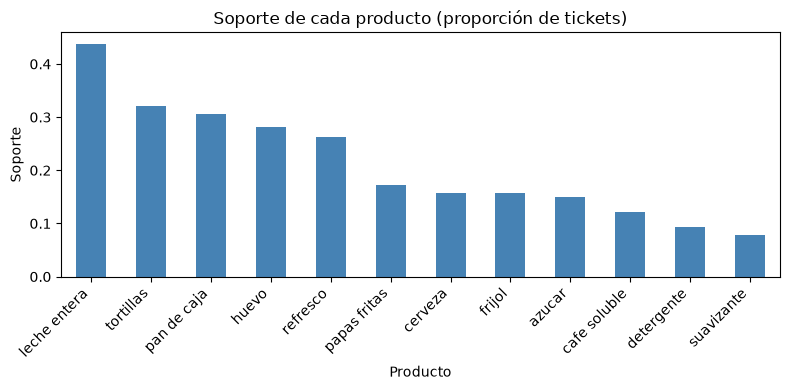

In [8]:
# El soporte de un producto es la media de su columna booleana
soporte = canasta.mean().sort_values(ascending=False)
print(soporte.round(3))

fig, ax = plt.subplots(figsize=(8, 4))
soporte.plot.bar(ax=ax, color="steelblue")
ax.set_title("Soporte de cada producto (proporción de tickets)")
ax.set_xlabel("Producto")
ax.set_ylabel("Soporte")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

**Interpretación.** La matriz tiene 2 998 tickets × 12 productos y ningún ticket vacío. La leche entera es, por mucho, el producto más frecuente: aparece en el 43.8 % de los tickets, seguida de tortillas (32.0 %) y pan de caja (30.6 %). Los menos frecuentes son detergente (9.2 %) y suavizante (7.8 %). Un producto tan popular como la leche aparecerá junto a casi cualquier otro solo por azar, algo que hay que tener en cuenta al evaluar las reglas.

### Tarea 6. Minería: soporte, confianza y *lift* de pares de productos

Con la matriz en 0 y 1, el producto matricial `X.T @ X` da en la celda $(A, B)$ el número de tickets que contienen $A$ y $B$; la diagonal es el número de tickets con cada producto. Después basta con dividir:

- `soporte` = tickets con $A$ y $B$ / total de tickets;
- `confianza` = soporte$(A, B)$ / soporte$(A)$;
- `lift` = confianza / soporte$(B)$.

In [9]:
X = canasta.astype(int)
n_tickets_validos = len(X)
conteos = X.T @ X

reglas = (conteos.stack()
          .rename_axis(["antecedente", "consecuente"])
          .reset_index(name="tickets"))
reglas = reglas[reglas["antecedente"] != reglas["consecuente"]].reset_index(drop=True)

reglas["soporte"] = reglas["tickets"] / n_tickets_validos
reglas["confianza"] = reglas["soporte"] / reglas["antecedente"].map(soporte)
reglas["lift"] = reglas["confianza"] / reglas["consecuente"].map(soporte)
reglas = reglas.drop(columns="tickets")

print("Número de reglas:", len(reglas))
reglas.head()

Número de reglas: 132


,antecedente,consecuente,soporte,confianza,lift
0,azucar,cafe soluble,0.070714,0.473214,3.897518
1,azucar,cerveza,0.024350,0.162946,1.030619
2,azucar,detergente,0.010674,0.071429,0.773079
3,azucar,frijol,0.020680,0.138393,0.882770
4,azucar,huevo,0.042362,0.283482,1.008161


Las 6 reglas de mayor *lift* entre las que tienen soporte de al menos 0.02:

In [10]:
frecuentes = reglas[reglas["soporte"] >= 0.02]
print("Reglas con soporte >= 0.02:", len(frecuentes))
frecuentes.sort_values("lift", ascending=False).head(6).round(3)

Reglas con soporte >= 0.02: 104


,antecedente,consecuente,soporte,confianza,lift
42,detergente,suavizante,0.039,0.426,5.435
113,suavizante,detergente,0.039,0.502,5.435
11,cafe soluble,azucar,0.071,0.582,3.898
0,azucar,cafe soluble,0.071,0.473,3.898
29,cerveza,papas fritas,0.092,0.580,3.351
90,papas fritas,cerveza,0.092,0.530,3.351


Y las 6 de mayor confianza:

In [11]:
frecuentes.sort_values("confianza", ascending=False).head(6).round(3)

,antecedente,consecuente,soporte,confianza,lift
11,cafe soluble,azucar,0.071,0.582,3.898
29,cerveza,papas fritas,0.092,0.580,3.351
90,papas fritas,cerveza,0.092,0.530,3.351
113,suavizante,detergente,0.039,0.502,5.435
0,azucar,cafe soluble,0.071,0.473,3.898
94,papas fritas,leche entera,0.080,0.464,1.061


**Interpretación.** Tres pares destacan con *lift* muy superior a 1, en ambas direcciones (el *lift* es simétrico; la confianza no):

- **detergente y suavizante:** *lift* 5.43. Se compran juntos 5.4 veces más de lo esperado con compras independientes, aunque el par aparece en solo el 3.9 % de los tickets.
- **café soluble y azúcar:** *lift* 3.90; el 58.2 % de quienes compran café soluble también llevan azúcar.
- **cerveza y papas fritas:** *lift* 3.35 y el mayor soporte de los tres (9.2 % de los tickets); el 58.0 % de quienes compran cerveza llevan papas.

La lista por confianza muestra la trampa: la sexta regla, **papas fritas → leche entera**, tiene una confianza de 0.464, casi tan alta como azúcar → café soluble (0.473), pero su *lift* es 1.06. Que casi la mitad de quienes compran papas también lleven leche no dice nada de las papas: casi la mitad de **todos** los tickets llevan leche (soporte 0.438). La confianza no tiene en cuenta la popularidad del consecuente; el *lift* sí, porque la divide entre el soporte de $B$. Por eso las reglas se evalúan con el *lift* (y con un soporte mínimo) y no solo con la confianza.

### Tarea 7. Interpretación: de las reglas a una recomendación

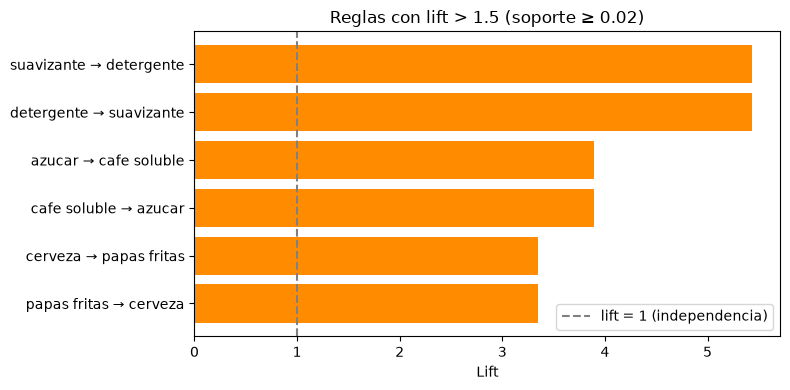

,antecedente,consecuente,soporte,confianza,lift
90,papas fritas,cerveza,0.092,0.530,3.351
29,cerveza,papas fritas,0.092,0.580,3.351
11,cafe soluble,azucar,0.071,0.582,3.898
0,azucar,cafe soluble,0.071,0.473,3.898
42,detergente,suavizante,0.039,0.426,5.435
113,suavizante,detergente,0.039,0.502,5.435


In [12]:
fuertes = frecuentes[frecuentes["lift"] > 1.5].sort_values("lift")
etiquetas = fuertes["antecedente"] + " → " + fuertes["consecuente"]

fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(etiquetas, fuertes["lift"], color="darkorange")
ax.axvline(1, color="gray", linestyle="--", label="lift = 1 (independencia)")
ax.set_title("Reglas con lift > 1.5 (soporte ≥ 0.02)")
ax.set_xlabel("Lift")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

fuertes[["antecedente", "consecuente", "soporte", "confianza", "lift"]].round(3)

**Recomendación para la gerente de mercadotecnia.**

1. **Cerveza y papas fritas** es el par más rentable de explotar: tiene el mayor soporte (9.2 % de los tickets) y un *lift* de 3.35. Conviene exhibir las botanas junto al refrigerador de cerveza y probar un combo de fin de semana.
2. **Café soluble y azúcar** (*lift* 3.90): colocar el azúcar en el pasillo del café o junto a él, y probar un cupón de azúcar al comprar café. Como más de la mitad de quienes compran café ya llevan azúcar, es mejor descontar **uno** de los dos productos para atraer la compra del otro que rebajar ambos.
3. **Detergente y suavizante** (*lift* 5.43, el más alto): un paquete o una exhibición conjunta puede aumentar la venta de suavizante, que es el producto menos frecuente.

Primero se probaría en una sucursal y se compararía con las otras dos durante algunas semanas, que corresponde al paso de "uso del conocimiento" del KDD.

**Limitación.** Las reglas miden asociación, no causalidad: no garantizan que una promoción de cerveza aumente la venta de papas. Además, los datos cubren solo un trimestre (julio–septiembre), así que pueden reflejar la temporada, y el análisis considera pares, no combinaciones de tres o más productos ni diferencias entre sucursales.

## Conclusiones

- El proceso KDD dio forma al proyecto: la meta de la gerente determinó qué datos seleccionar, la preparación fue el paso más laborioso y la minería en sí se resolvió con unas pocas operaciones matriciales.
- La calidad de los datos cambia el resultado: sin normalizar, 41 nombres de producto y 381 duplicados ocultos habrían fragmentado las canastas y distorsionado los conteos.
- Tres pares de productos se compran juntos mucho más de lo esperado por azar: detergente y suavizante (*lift* 5.43), café soluble y azúcar (3.90) y cerveza y papas fritas (3.35). Son los candidatos para promociones conjuntas y acomodo en anaquel.
- La confianza sola engaña cuando el consecuente es muy popular: las reglas hacia la leche entera tienen confianza cercana a 0.45 pero *lift* cercano a 1.
- El siguiente ciclo del KDD debería usar el código de barras como clave, ampliar el periodo, comparar sucursales y medir el efecto real de las acciones con una prueba piloto.